<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [Grammar Checker](https://github.com/Query-farm/vgi-grammar)

Find, count, and auto-correct grammar, style, and spelling issues in free text using the open-source LanguageTool engine.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-grammar/blob/main/notebooks/01_recheck_automatic_corrections.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-grammar/blob/main/notebooks/README.md)


## 01 · Recheck automatic corrections before accepting them

**Does applying suggested edits mean a draft is ready to use?**
We will check ten synthetic text records with LanguageTool, apply the worker's first
suggestions, and check the resulting text again. One sample gains a detected issue
after the first pass. Another has no detected writing issues but makes an intentionally
false factual claim. Empty and missing text need their own statuses too.

This is a local text-processing example: it sends no messages and uses no hosted
language-model or LanguageTool API. All drafts are synthetic, English, and ASCII.

### Choose the number of correction passes

The default runs one pass; the experiment changes only `CORRECTION_PASSES` to `2`.
Each pass uses the original language choice, `en-US`, and applies the first suggestion
for each non-overlapping issue from right to left. Repeated correction is an experiment,
not a guarantee of convergence or preserved meaning. [Run instructions](README.md).

In [1]:
CORRECTION_PASSES = 1

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.9":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.9"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the kernel, then run all cells.")

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from IPython.display import display
from vgi_notebooks import check_runtime, connect, prepare
from vgi_notebooks.presentation import finish, prose, theme

check_runtime()
if type(CORRECTION_PASSES) is not int or CORRECTION_PASSES not in (1, 2):
    raise ValueError("CORRECTION_PASSES must be 1 or 2.")
prepare("grammar")
theme()
SOURCE = "Source: ten synthetic ASCII drafts · LanguageTool 6.8 / en-US · VGI Grammar v0.4.0"
session = connect(globals())

### Connect to the released worker and choose a supported dialect

The short launcher runs only the reviewed **v0.4.0** release. Its hash-verified companion records the public JAR's exact SHA-256 and checks cached bytes before every launch. A separate locked launcher environment supplies **Java 21.0.8** through `jdk4py==21.0.8.2` and checks the actual binary version; it does not use system Java or change the notebook kernel. Initial downloads need network access, then LanguageTool runs locally. The launcher supports macOS and glibc Linux, including the Linux environment used by Colab; it uses a POSIX cache lock.

The shared bootstrap retrieves the immutable launcher and its lock without manual cloning. Colab installs only the base shared package; local publication adds `[runner]`. SQL credentials start in an empty temporary directory with persistent secrets disabled. No text is sent to a hosted service.

Ask the worker which language codes this release ships before choosing a dialect. Materialize that answer once, select **en-US**, and require that exact code to exist before editing any draft. This release ships English rules; choosing a different supported dialect can change the matches.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'grammar' (TYPE vgi,
 LOCATION 'uv run --locked --no-project --python 3.13 grammar_release.py v0.4.0');
CREATE TABLE supported_languages AS SELECT * FROM grammar.main.grammar_languages();
SELECT code,name,code='en-US' AS selected_for_this_notebook
FROM supported_languages ORDER BY code;

,code,name,selected_for_this_notebook
0,en,English,False
1,en-AU,English (Australian),False
2,en-CA,English (Canadian),False
3,en-GB,English (GB),False
4,en-NZ,English (New Zealand),False
5,en-US,English (US),True
6,en-ZA,English (South African),False


In [5]:
%%sql language_choice <<
SELECT code,name FROM supported_languages WHERE code='en-US';

In [6]:
display(language_choice)
assert len(language_choice) == 1 and language_choice.code.iloc[0] == "en-US"
prose(
    f"The worker advertises **{language_choice.name.iloc[0]} (`{language_choice.code.iloc[0]}`)**. "
    "Every correction and recheck below explicitly uses that selected dialect. "
    "Availability establishes which rules can run; it does not establish that those rules fit every author's context."
)

,code,name
0,en-US,English (US)


The worker advertises **English (US) (`en-US`)**. Every correction and recheck below explicitly uses that selected dialect. Availability establishes which rules can run; it does not establish that those rules fit every author's context.

### Keep the original and each candidate version

Use the scalar `correct` function on a column of text. Materializing each pass makes
the original and edited versions available for inspection and avoids recomputing worker
calls during later aggregation. A second pass is only populated when requested.

`correct` is an editing policy: it selects the first suggestion, skips overlaps and
leaves issues without suggestions alone. We keep row IDs and original input state;
neither an empty string nor SQL NULL becomes a completed draft because a checker ran.

In [7]:
%%sql
CREATE TABLE drafts(record_id INTEGER,original_text VARCHAR);
INSERT INTO drafts VALUES
 (1,'Thanks for you order, it will ship tomorow.'),
 (2,'I could of done it better.'),
 (3,'This are a test of the the system.'),
 (4,'He dont know nothing about it.'),
 (5,'Your package has been delivered.'),
 (6,'Its a nice day, isnt it?'),
 (7,'I has a apple.'),
 (8,'The Moon is made of cheese.'),
 (9,''),
 (10,NULL);
CREATE TABLE pass_one AS
 SELECT record_id,grammar.main.correct(original_text,'en-US') AS candidate_text FROM drafts;
CREATE TABLE pass_two AS
 SELECT record_id,grammar.main.correct(candidate_text,'en-US') AS candidate_text
 FROM pass_one WHERE {{ CORRECTION_PASSES }}=2;
CREATE TABLE versions AS
 SELECT record_id,0 AS pass,original_text AS candidate_text FROM drafts
 UNION ALL SELECT record_id,1,candidate_text FROM pass_one
 UNION ALL SELECT record_id,2,candidate_text FROM pass_two;
SELECT * FROM versions WHERE record_id IN (3,4) ORDER BY record_id,pass;

,record_id,pass,candidate_text
0,3,0,This are a test of the the system.
1,3,1,These is a test of the system.
2,4,0,He dont know nothing about it.
3,4,1,He don't know nothing about it.


### Recheck the candidate text

`grammar_count` counts detected rule matches, and `is_grammatical` reports whether that
count is zero. Those names do not establish that a sentence is true, appropriate, or
complete. We check both functions against the same stored text and language.

The actual release returns **0 / true for an empty string**, and **NULL / NULL for a
SQL NULL input**. A scalar's internal per-row error can also return NULL, so an
unavailable check must remain visible rather than being converted to zero.

In [8]:
%%sql
CREATE TABLE scored AS
 SELECT v.*,grammar.main.grammar_count(candidate_text,'en-US') AS issues,
        grammar.main.is_grammatical(candidate_text,'en-US') AS zero_issue_flag
 FROM versions v;
CREATE TABLE assessed AS
 SELECT s.*,d.original_text,
 CASE WHEN d.original_text IS NULL THEN 'Missing text'
      WHEN d.original_text='' THEN 'Empty text'
      WHEN s.issues IS NULL THEN 'Check unavailable'
      WHEN s.issues>0 THEN 'Issues detected'
      ELSE 'No issues detected' END AS review_status
 FROM scored s JOIN drafts d USING(record_id);
SELECT record_id,pass,candidate_text,issues,zero_issue_flag,review_status
FROM assessed WHERE record_id IN (4,8,9,10) ORDER BY record_id,pass;

,record_id,pass,candidate_text,issues,zero_issue_flag,review_status
0,4,0,He dont know nothing about it.,1,False,Issues detected
1,4,1,He don't know nothing about it.,2,False,Issues detected
2,8,0,The Moon is made of cheese.,0,True,No issues detected
3,8,1,The Moon is made of cheese.,0,True,No issues detected
4,9,0,,0,True,Empty text
5,9,1,,0,True,Empty text
6,10,0,None,<NA>,<NA>,Missing text
7,10,1,None,<NA>,<NA>,Missing text


### Inspect the suggestions behind one edit

`grammar_check` returns one row per detected issue, including its category, flagged
text and ordered suggestions. The table function accepts literal text; the scalar
functions above are the convenient way to process a text column.

This is row 4's original text. Compare its first suggestion with the version history
and the subsequent issue count. One local spelling fix can expose additional matches
in a later check. Offsets refer to the original string (zero-based Java UTF-16 units);
our ASCII sample makes them directly readable.

In [9]:
%%sql
CREATE TABLE focus_issues AS
 SELECT * FROM grammar.main.grammar_check('He dont know nothing about it.',language:='en-US');
SELECT rule_id,category,"offset",length,bad_text,suggestions,message
FROM focus_issues ORDER BY "offset",rule_id;

,rule_id,category,offset,length,bad_text,suggestions,message
0,EN_CONTRACTION_SPELLING,Possible Typo,3,4,dont,[don't],Possible spelling mistake found.


### Compare detected issues on the same eight nonempty drafts

Counts are observations under one rule set, not comparable writing-quality scores.
The chart retains zero counts and shows increases as well as decreases. Empty and
missing records remain in the population audit below, outside this comparison.

In [10]:
%%sql comparison <<
SELECT b.record_id,b.original_text,b.issues AS original_issues,
       a.candidate_text,a.issues AS candidate_issues,
       a.issues-b.issues AS issue_change
FROM assessed b JOIN assessed a USING(record_id)
WHERE b.pass=0 AND a.pass={{ CORRECTION_PASSES }}
  AND b.original_text IS NOT NULL AND b.original_text!=''
ORDER BY b.record_id;

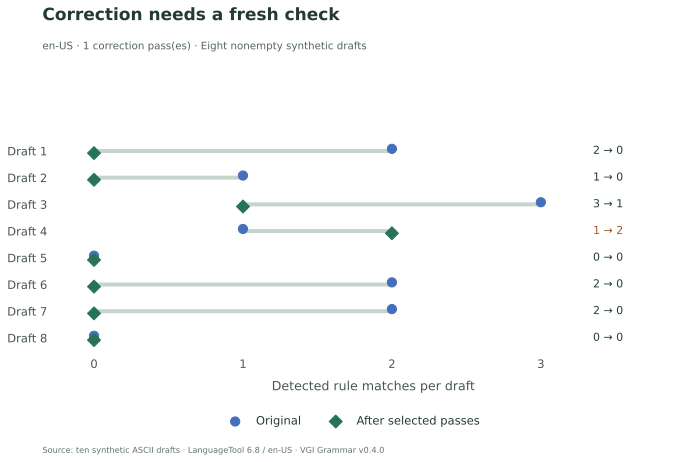

After **1 pass(es)**, detected matches total **3**, compared with **11** originally. **2 of 8 nonempty drafts** still have detected issues; **1** have more matches than their original version. Review the candidate wording as well as the count: this sample does not measure preserved meaning.

In [11]:
fig, ax = plt.subplots(figsize=(10, 6.8))
y = np.arange(len(comparison))
for i, row in enumerate(comparison.itertuples()):
    ax.plot([row.original_issues, row.candidate_issues], [i, i], color="#c7d4cd", lw=4, zorder=1)
ax.scatter(comparison.original_issues, y - 0.08, s=85, color="#456fba", label="Original", zorder=3)
ax.scatter(
    comparison.candidate_issues,
    y + 0.08,
    s=85,
    color="#267358",
    marker="D",
    label="After selected passes",
    zorder=3,
)
for i, row in enumerate(comparison.itertuples()):
    ax.text(
        3.35,
        i,
        f"{row.original_issues} → {row.candidate_issues}",
        va="center",
        fontsize=11,
        color="#a65332" if row.issue_change > 0 else "#253d31",
    )
ax.set_yticks(y, [f"Draft {r.record_id}" for r in comparison.itertuples()])
ax.invert_yaxis()
ax.set_xlim(-0.25, 4)
ax.set_xticks([0, 1, 2, 3])
ax.set_xlabel("Detected rule matches per draft")
ax.grid(axis="y", visible=False)
fig.legend(
    *ax.get_legend_handles_labels(),
    loc="lower center",
    bbox_to_anchor=(0.5, 0.09),
    ncol=2,
    frameon=False,
)
finish(
    fig,
    "Correction needs a fresh check",
    f"en-US · {CORRECTION_PASSES} correction pass(es) · Eight nonempty synthetic drafts",
    SOURCE,
    name=f"recheck-counts-passes-{CORRECTION_PASSES}",
)
increased = int((comparison.issue_change > 0).sum())
remaining = int((comparison.candidate_issues > 0).sum())
prose(
    f"After **{CORRECTION_PASSES} pass(es)**, detected matches total **{int(comparison.candidate_issues.sum())}**, "
    f"compared with **{int(comparison.original_issues.sum())}** originally. "
    f"**{remaining} of {len(comparison)} nonempty drafts** still have detected issues; "
    f"**{increased}** have more matches than their original version. "
    "Review the candidate wording as well as the count: this sample does not measure preserved meaning."
)

### Keep the denominator and availability states visible

Count records, rather than issue rows, when measuring the review population. Every
stage below contains the same ten records. The blank draft and missing draft remain
separate from nonempty text with no detected issues. An unavailable check would also
have its own status; there are none among this sample's nonempty drafts.

In [12]:
%%sql population <<
WITH stages AS (SELECT DISTINCT pass FROM assessed),
 states AS (SELECT * FROM (VALUES
   (1,'Issues detected'),(2,'No issues detected'),(3,'Empty text'),
   (4,'Missing text'),(5,'Check unavailable')) v(position,review_status)),
 counts AS (SELECT pass,review_status,count(*) AS records FROM assessed GROUP BY ALL)
SELECT s.pass,t.position,t.review_status,coalesce(c.records,0) AS records
FROM stages s CROSS JOIN states t LEFT JOIN counts c
 ON c.pass=s.pass AND c.review_status=t.review_status ORDER BY s.pass,t.position;

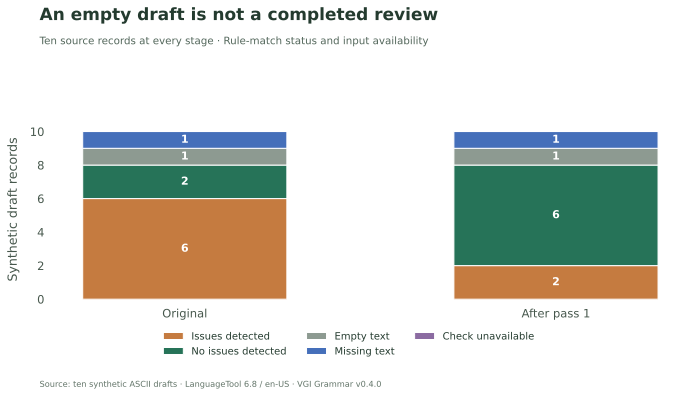

The final population contains **6 nonempty drafts with no detected issues**, **2 with detected issues**, **1 empty** and **1 missing**. Draft 8's intentionally false claim about the Moon still has zero detected issues. The worker checks language rules; this result does not verify that claim.

In [13]:
fig, ax = plt.subplots(figsize=(10, 5.8))
stages = sorted(population["pass"].unique())
bottom = np.zeros(len(stages))
colors = ["#c57b40", "#267358", "#8d9a91", "#456fba", "#8b6ba1"]
for (status, group), color in zip(
    population.groupby("review_status", sort=False), colors, strict=True
):
    values = group.sort_values("pass").records.to_numpy(dtype=int)
    ax.bar(stages, values, bottom=bottom, color=color, label=status, width=0.55)
    for x, v, b in zip(stages, values, bottom, strict=True):
        if v:
            ax.text(x, b + v / 2, str(v), ha="center", va="center", color="white", weight="bold")
    bottom += values
ax.set_xticks(stages, ["Original" if p == 0 else f"After pass {p}" for p in stages])
ax.set_ylim(0, 10.7)
ax.set_ylabel("Synthetic draft records")
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(axis="x", visible=False)
fig.legend(
    *ax.get_legend_handles_labels(),
    loc="lower center",
    bbox_to_anchor=(0.5, 0.11),
    ncol=3,
    frameon=False,
    fontsize=10,
)
finish(
    fig,
    "An empty draft is not a completed review",
    "Ten source records at every stage · Rule-match status and input availability",
    SOURCE,
    name=f"review-population-passes-{CORRECTION_PASSES}",
)
latest = population[population["pass"] == CORRECTION_PASSES].set_index("review_status").records
prose(
    f"The final population contains **{int(latest['No issues detected'])} nonempty drafts with no detected issues**, "
    f"**{int(latest['Issues detected'])} with detected issues**, "
    f"**{int(latest['Empty text'])} empty** and **{int(latest['Missing text'])} missing**. "
    "Draft 8's intentionally false claim about the Moon still has zero detected issues. "
    "The worker checks language rules; this result does not verify that claim."
)

### Check the audit, not a promise that every edit improves text

The assertions reconcile versions, counts, availability, and the detailed table
function. We deliberately do not assert that counts always decrease or that zero
means publication-ready. Those are separate editorial decisions.

In [14]:
%%sql checks <<
SELECT 'Every requested stage retains ten unique record IDs' AS invariant,
 NOT EXISTS(SELECT pass FROM assessed GROUP BY pass HAVING count(*)!=10 OR count(DISTINCT record_id)!=10)
 AND (SELECT count(DISTINCT pass) FROM assessed)={{ CORRECTION_PASSES }}+1 AS passed
UNION ALL SELECT 'Stored original text is preserved at stage zero',
 NOT EXISTS(SELECT 1 FROM assessed WHERE pass=0 AND candidate_text IS DISTINCT FROM original_text)
UNION ALL SELECT 'Missing inputs remain missing with unavailable check results',
 NOT EXISTS(SELECT 1 FROM assessed WHERE original_text IS NULL AND
   (candidate_text IS NOT NULL OR issues IS NOT NULL OR zero_issue_flag IS NOT NULL OR review_status!='Missing text'))
UNION ALL SELECT 'Empty inputs remain empty with the actual zero/true worker result',
 NOT EXISTS(SELECT 1 FROM assessed WHERE original_text='' AND
   (candidate_text IS DISTINCT FROM '' OR issues IS DISTINCT FROM 0 OR zero_issue_flag IS DISTINCT FROM true OR review_status!='Empty text'))
UNION ALL SELECT 'All nonempty sample checks are available and nonnegative',
 NOT EXISTS(SELECT 1 FROM assessed WHERE original_text IS NOT NULL AND original_text!=''
   AND (issues IS NULL OR issues<0 OR zero_issue_flag IS NULL))
UNION ALL SELECT 'Boolean result agrees with the count on checked records',
 NOT EXISTS(SELECT 1 FROM assessed WHERE issues IS NOT NULL AND zero_issue_flag IS DISTINCT FROM (issues=0))
UNION ALL SELECT 'Original detailed issue rows reconcile with scalar count',
 (SELECT count(*) FROM focus_issues)=(SELECT issues FROM assessed WHERE record_id=4 AND pass=0)
UNION ALL SELECT 'Detailed spans identify the original ASCII text',
 NOT EXISTS(SELECT 1 FROM focus_issues WHERE bad_text IS DISTINCT FROM
   substr('He dont know nothing about it.',"offset"+1,length))
UNION ALL SELECT 'Repeated passes preserve the deliberately false claim unchanged',
 NOT EXISTS(SELECT 1 FROM assessed WHERE record_id=8 AND candidate_text IS DISTINCT FROM original_text)
UNION ALL SELECT 'The selected version contains all source rows',
 (SELECT count(*) FROM assessed WHERE pass={{ CORRECTION_PASSES }})=(SELECT count(*) FROM drafts);

In [15]:
display(checks)
assert checks.passed.eq(True).all(), checks.loc[~checks.passed].to_dict("records")
prose(
    f"**{len(checks)} audit checks passed.** These checks establish how this sample was processed, "
    "not factual accuracy or editorial approval of the candidate drafts."
)

,invariant,passed
0,Every requested stage retains ten unique recor...,True
1,Stored original text is preserved at stage zero,True
2,Missing inputs remain missing with unavailable...,True
3,Empty inputs remain empty with the actual zero...,True
4,All nonempty sample checks are available and n...,True
5,Boolean result agrees with the count on checke...,True
6,Original detailed issue rows reconcile with sc...,True
7,Detailed spans identify the original ASCII text,True
8,Repeated passes preserve the deliberately fals...,True
9,The selected version contains all source rows,True


**10 audit checks passed.** These checks establish how this sample was processed, not factual accuracy or editorial approval of the candidate drafts.

### Experiment: allow one more correction pass

Change only `CORRECTION_PASSES` from `1` to `2`, restart and run all. Predict the
second versions of drafts 3 and 4 before reading them. Compare the new issue counts,
the exact candidate wording, and the population chart. Does the empty draft become
usable? Does the factual claim in draft 8 become true?

This small constructed example is not a benchmark for LanguageTool. Counts depend
on the shipped rules and language choice. Review suggestions and meaning in your own
context before using edited text; keep the original for comparison. Reset to `1` for
the saved default.

In [16]:
session.close()
plt.close("all")

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-grammar](https://github.com/Query-farm/vgi-grammar)
